In [175]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder, RobustScaler, FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer

from machinelearningproject_ct4101.utils import plot_distribution, save_splits



SEED = 1337

raw_dataset_path = "../../../data/raw/online_shoppers_intention.csv"
splits_path = "../../../data/processed/"

___
### Key Obervations
- No NaN values
- 125 duplicated rows, however they correspond to very short visits, and are more than likely just very short sessions with similar activity, so need need to dedupe
- Need to scale/transform the numerical values, a majority of them are heavily right skewed with a few large outliers. 
- Target class is unevenly distributed, roughly 85% of visits did not make a purchase, so a model predicting False 100% of the time would still obtain roughly 85% accuracy.
- We need to stratify the train/test splits
- `Month` and `VisitorType` are not encoded, we'll have to encode them
- Our Month column is missing Janurary and April
- Some columns are Ordinal Encoded when they're Nominal categories, we should reencode
___

#### Load the data

In [176]:
df = pd.read_csv(raw_dataset_path)

___
#### Need to:
1. Log Transform Numerical Values to fix large right skew
2. Encode `Month` with cyclical encoding
3. Create the train/test/val splits and stratify on Revenue
4. Encode `VisitorType` and other inccorectly encoded features with one hot and `RobustScale` to scale data
5. Save the train/test/val splits
___

#### 1. Log Transform Numerical Values
- To reduce heavily right skewed data we log transform our numerical values
- Since a log transform does not learn values from the data, it will not introduce data leakage

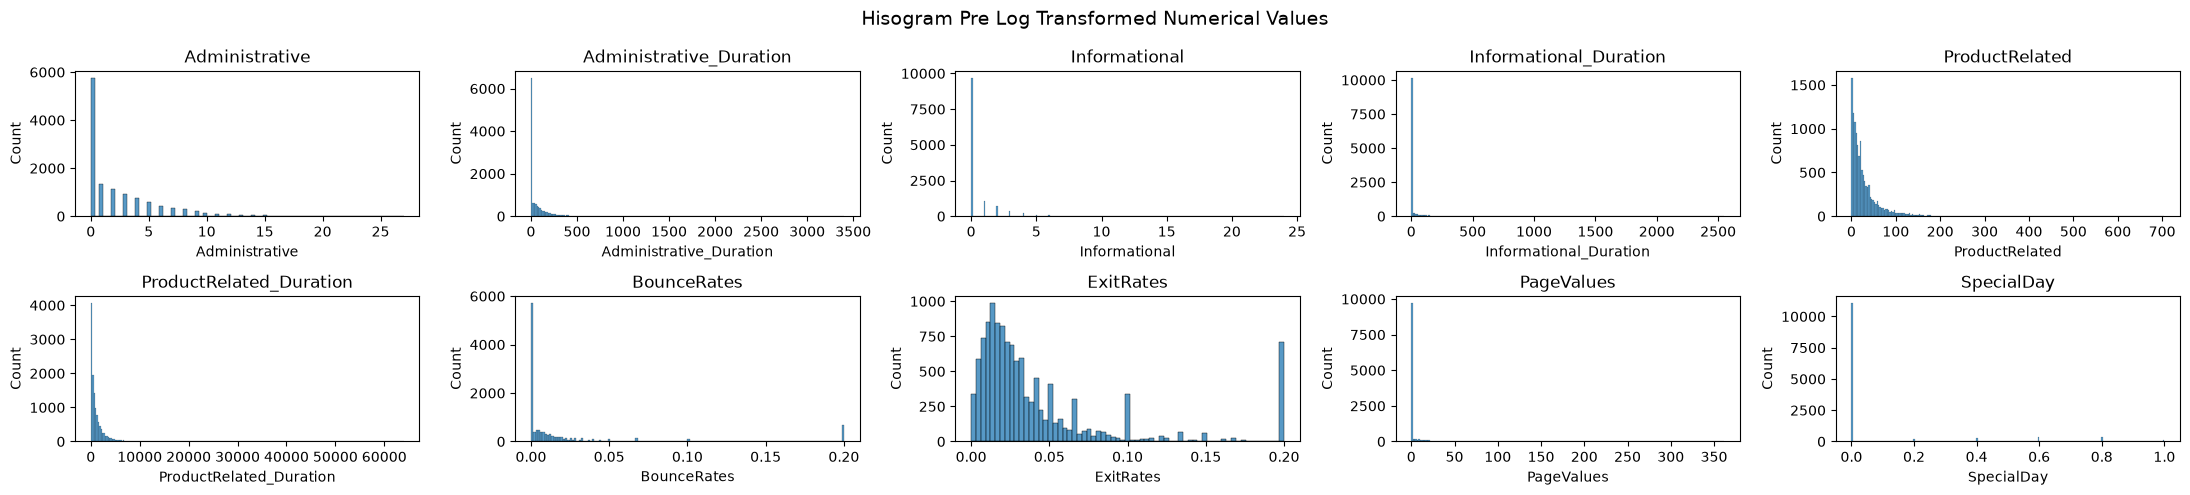

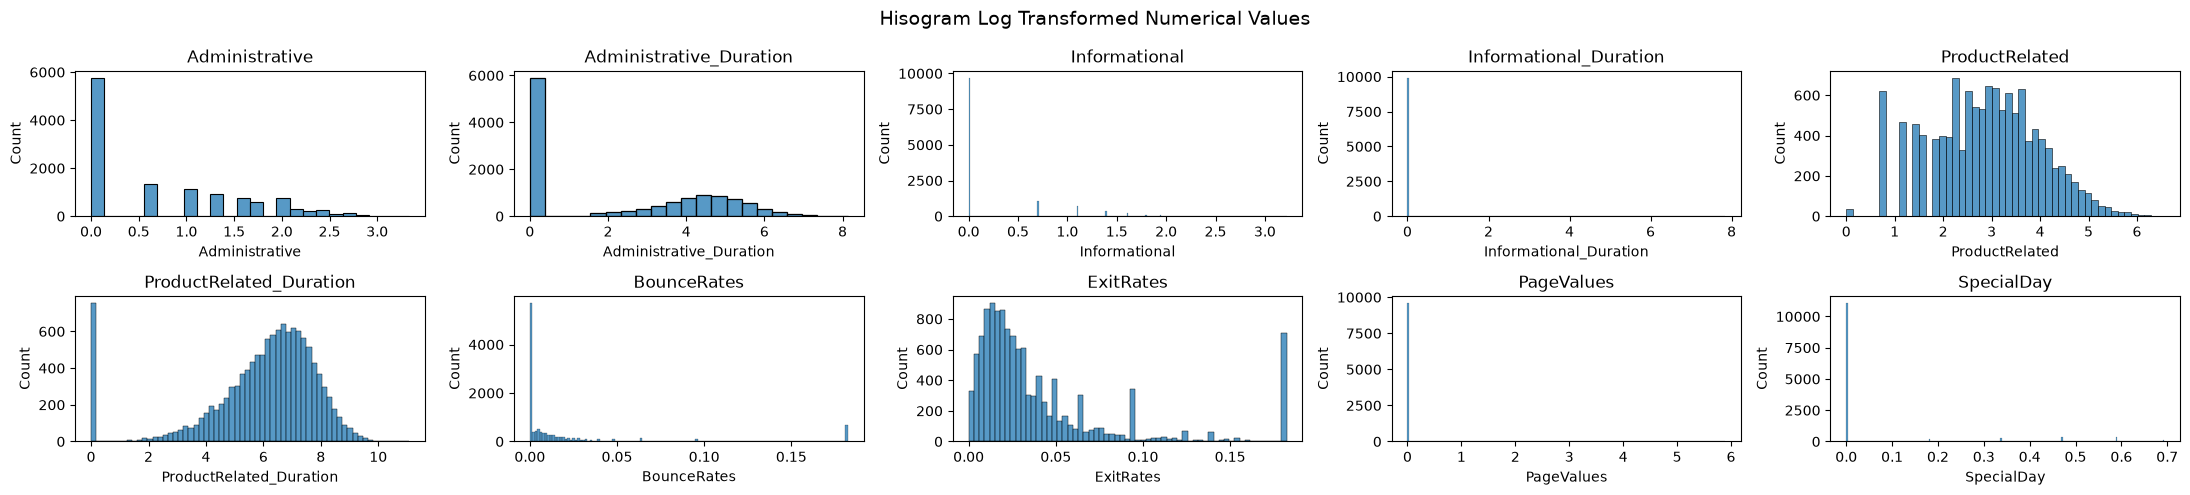

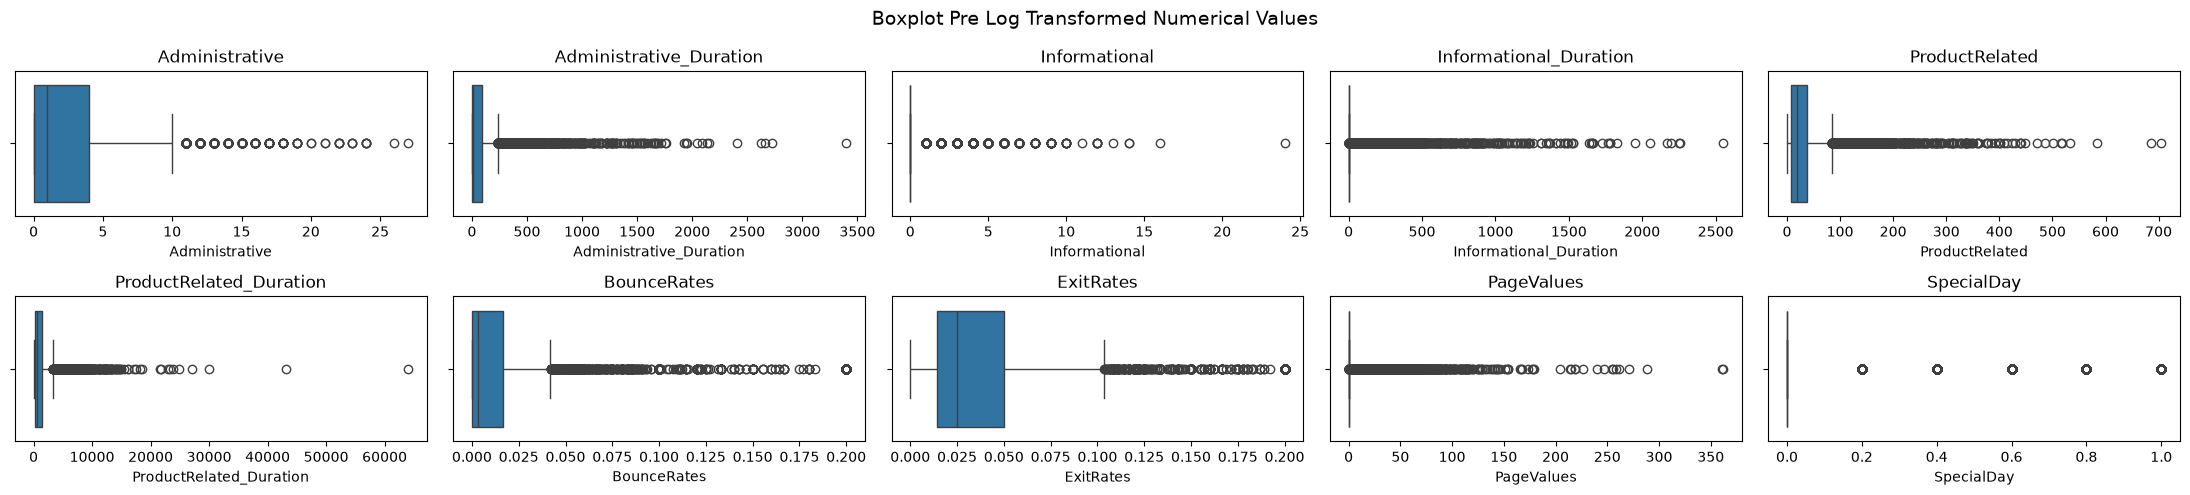

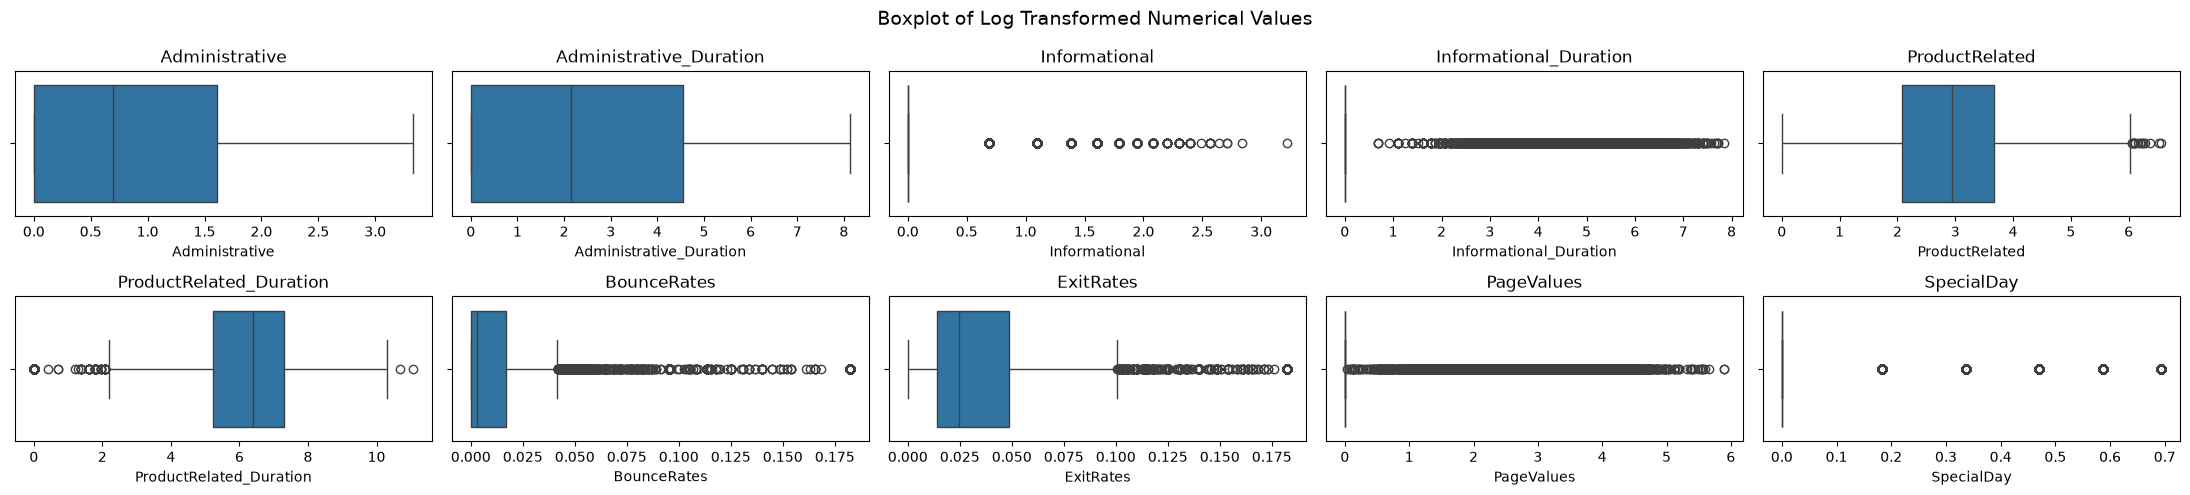

In [177]:
# Numerical Columns
numerical = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']


df_log = df.copy(deep=True)

for col in numerical:
    df_log[col] = np.log1p(df[col])

plot_distribution(df, "hist", 2, 5, "Hisogram Pre Log Transformed Numerical Values", numerical)
plot_distribution(df_log, "hist", 2, 5, "Hisogram Log Transformed Numerical Values", numerical)
plot_distribution(df, "boxplot", 2, 5, "Boxplot Pre Log Transformed Numerical Values", numerical)
plot_distribution(df_log, "boxplot", 2, 5, "Boxplot of Log Transformed Numerical Values", numerical)

____
#### 2. Encode Month With Cyclical Encoding
- We saw our `Months` column was not encoded. 
- Since months is inherently temporal, it can benefit from cyclical encoding, where "May" is close to "June" rather than one hot where the model cannot see a relationships
- Since we know all months in advance, encoding before splitting will not data leak
- We follow [scikit-learns example](https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html#trigonometric-features)

In [178]:
# Months in the dataset
list(df_log["Month"].unique())

['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']

In [179]:
# Dict to map month to a float
month_nums = {
    "Jan": 0.0,
    "Feb": 1.0,
    "Mar": 2.0,
    "Apr": 3.0,
    "May": 4.0,
    "June": 5.0,
    "Jul": 6.0,
    "Aug": 7.0,
    "Sep": 8.0,
    "Oct": 9.0,
    "Nov": 10.0,
    "Dec": 11.0
}

# Map string month to float 
df_log["MonthFloat"] = df_log["Month"].map(month_nums)
df_log["Month"].head(3), df_log["MonthFloat"].head(3)

(0    Feb
 1    Feb
 2    Feb
 Name: Month, dtype: str,
 0    1.0
 1    1.0
 2    1.0
 Name: MonthFloat, dtype: float64)

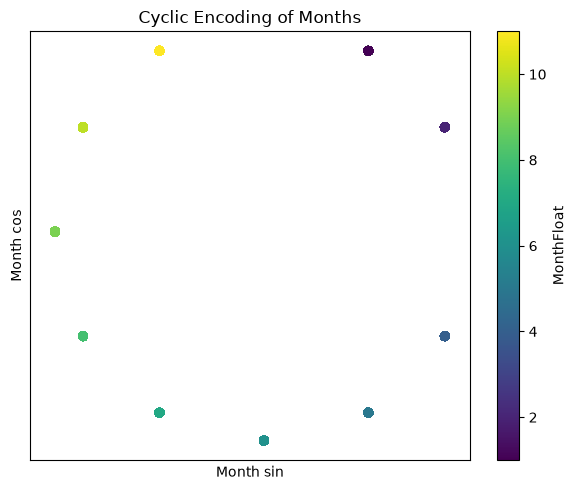

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue', 'Month_sin', 'Month_cos'],
      dtype='str')

In [180]:
# Source :
# https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html#trigonometric-features
def sin_transformer(period): 
    return FunctionTransformer(lambda x: np.sin(x / period * 2 * np.pi), feature_names_out="one-to-one")

def cos_transformer(period):
    return FunctionTransformer(lambda x: np.cos(x / period * 2 * np.pi), feature_names_out="one-to-one")

# Create cyclically encoded columns
df_log["Month_sin"] = sin_transformer(12).fit_transform(df_log[["MonthFloat"]])["MonthFloat"]
df_log["Month_cos"] = cos_transformer(12).fit_transform(df_log[["MonthFloat"]])["MonthFloat"]

# Plot the results
plt.figure(figsize=(6,5))
sc = plt.scatter(df_log["Month_sin"], df_log["Month_cos"], c= df_log["MonthFloat"])
plt.colorbar(sc, label="MonthFloat")
plt.title("Cyclic Encoding of Months")
plt.xlabel("Month sin")
plt.ylabel("Month cos")
plt.axis('equal')
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()

# Drop the month and month float since our model won't train on them 
df_log = df_log.drop(columns=["MonthFloat", "Month"])
df_log.columns

___
#### 3. Create the train/test/val splits

In [181]:
X = df_log.drop(columns=["Revenue"])
y = df_log["Revenue"]

X.shape, y.shape

((12330, 18), (12330,))

In [182]:
# 70 - 30 split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size = 0.3, random_state=SEED, stratify=y)

# 50 - 50 split so that val gets 15% and train gets 15%
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size = 0.5, random_state=SEED, stratify=y_temp)

# Ensure split was correct
X_train.shape, X_test.shape, X_val.shape, y_train.shape, y_test.shape, y_val.shape

((8631, 18), (1849, 18), (1850, 18), (8631,), (1849,), (1850,))

___
#### 4. Encode `VisitorType` and other inccorectly encoded features with one hot and `RobustScale` to scale data
- `VisitorType` consists of nominal categories, so one hot encoding is a good baseline
- Several other category columns nominal categorical features are using ordinal encoding, we should reencode them 
- As mentioned, our data is one different ranges with many outliers, `RobustScaler` helps us with this

In [183]:
# Numerical columns
numerical_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']


categorical_cols = ["OperatingSystems", "Browser", "Region","TrafficType", "VisitorType"]


# One hot encoder for VisitorType
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# Pipeline for visitor
categorical_pipe = make_pipeline(encoder)

# Pipeline for numerical columns
numerical_pipe = make_pipeline(RobustScaler())

# Process the dataset
preprocess = ColumnTransformer([
    ("num", numerical_pipe, numerical_cols),
    ("cat", categorical_pipe, categorical_cols)
], remainder="passthrough")

# To keep headers and remove processing step from col name
preprocess.set_output(transform="pandas")
preprocess.set_params(verbose_feature_names_out=False)

# Fit on train, the transform remaining
X_train = preprocess.fit_transform(X_train)
X_test = preprocess.transform(X_test)
X_val = preprocess.transform(X_val)

___
### 5. Save the train/test/val splits

In [184]:
X_train.columns
save_splits(splits_path, X_train, X_test, X_val, y_train, y_test, y_val)
